In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [30]:
df = pd.read_csv("exoplanet_data.csv", comment = "#")

In [ ]:
print(df.shape)
#columns:599 row:92
print(df.columns)
#'pl_orbsmaxerr1'(???), pl_bmasseerr2','pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1'


(599, 92)
Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 's

(599, 6)
    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
0   7 CMa c    7 CMa  Radial Velocity         NaN     NaN   0.912000
1   7 CMa c    7 CMa  Radial Velocity         NaN     NaN   0.870000
2  DMPP-1 b   DMPP-1  Radial Velocity         NaN     NaN   0.052859
3  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
4  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
594    bet Pic c    bet Pic  Radial Velocity         NaN     NaN       9.00
595  eps Ind A b  eps Ind A  Radial Velocity        K2 V     NaN       3.25
596  eps Ind A b  eps Ind A  Radial Velocity        K5 V     NaN       6.50
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0       6.31
598  eps Ind A b  eps Ind A  Radial Velocity         NaN     NaN       7.63
Index(['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt',
       'pl_bmassj'],
      dtype='str')
discove

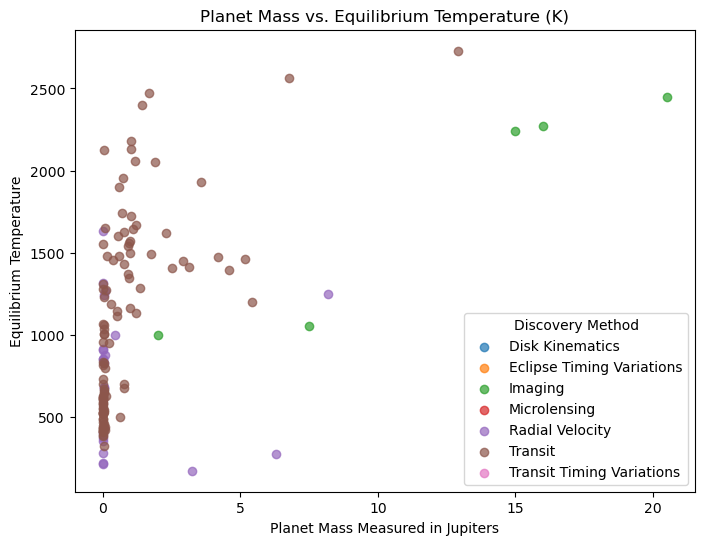

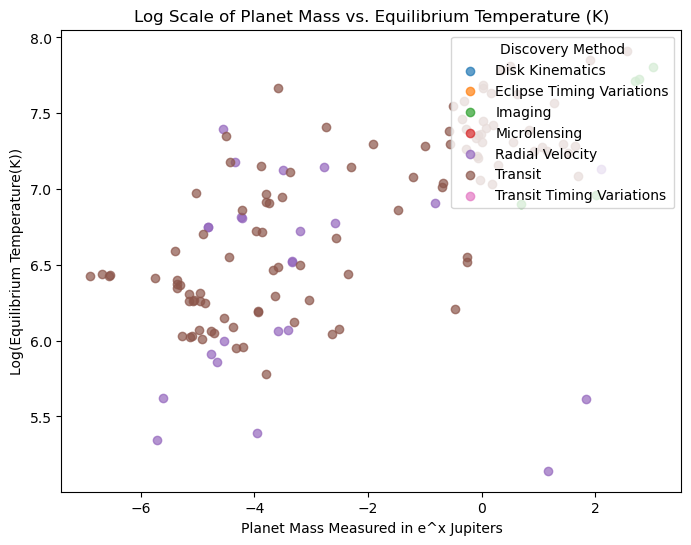

In [85]:
# Planet Name - pl_name - name of planet 
# Host Name - hostname - name of star (most common name used in literature)
# Discovery Method - discoverymethod - discovery method i.e. transit, radial velocity, etc
# Spectral Type - st_spectype - Star's spectral type based on the Morgan-Keenan system like O, B, A etc
# Equilibrium Temperature [K] - pl_eqt - planet's temperature modeled by a blackbody only heated by its star OR temperature based on luminosity (if directly imaged)
# Planet Mass or Mass*sin(i) [Jupiter Mass] - pl_bmassj - planet mass (best stinate) measured in units of Jupiters 

small_df=df[['pl_name','hostname','discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']].copy()
print(small_df.shape)
print(small_df.head())
print(small_df.tail())
print(small_df.columns)

method_counts = df['discoverymethod'].value_counts()
print(method_counts)
# Transit 0 measuring dips in a star's luminosity caused by a planet passing in front of it 
# Radial Velocity - measureing periodic redshift in blueshift of the star's light 
# Microlensing - using the gravity of a closer star to bend and therefore amplify the light of a more distant star 
# Imaging - just collecting that planet's reflected/emitted light 
# Transit Timing Variations - Watching to see if a known exoplanet's periodic transit is made irregular by another undetected exoplanet 
# Eclipse Timing Variations - Measuring, in binary star systems, periodic deivations in predicted eclipsing 
# Disk Kinematics - measuring perturbations of the star system's rotating disc of gas and dust

plt.figure(figsize=(8, 6))

for discovery_method, group in df.groupby('discoverymethod'):
    plt.scatter(
        group['pl_bmassj'], 
        group['pl_eqt'], 
        alpha=0.7, 
        label=discovery_method)

plt.title('Planet Mass vs. Equilibrium Temperature (K)')
plt.xlabel('Planet Mass Measured in Jupiters')
plt.ylabel('Equilibrium Temperature') 
plt.legend(title='Discovery Method', loc='lower right')
plt.show()


plt.figure(figsize=(8, 6))

for discovery_method, group in df.groupby('discoverymethod'):
    plt.scatter(
        np.log(group['pl_bmassj']), 
        np.log(group['pl_eqt']), 
        alpha=0.7, 
        label=discovery_method)

plt.title('Log Scale of Planet Mass vs. Equilibrium Temperature (K)')
plt.xlabel('Planet Mass Measured in e^x Jupiters')
plt.ylabel('Log(Equilibrium Temperature(K))') 
plt.legend(title='Discovery Method', loc='upper right')
plt.show()

#it's not showing anything except the methods where temperature and mass can both be detected/calculated 


pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object
Index: 597


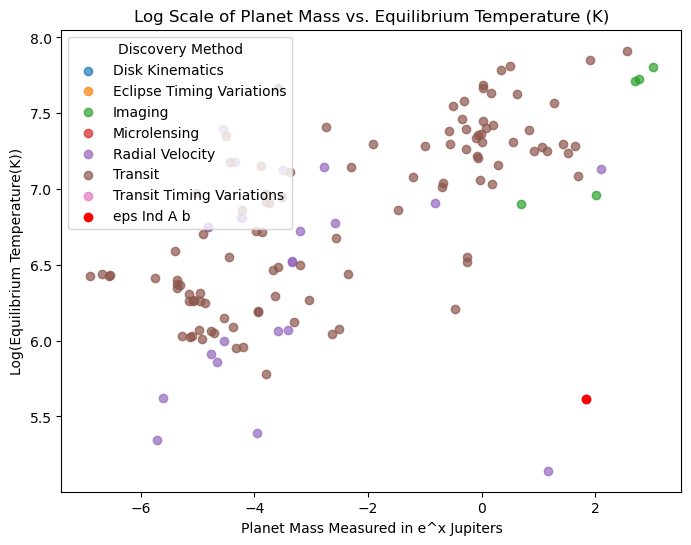

In [84]:
five_jupiters = small_df[small_df['pl_bmassj']>5]
coldest_index = five_jupiters['pl_eqt'].idxmin()
coldest_planet = small_df.loc[coldest_index]
print(coldest_planet)
print("Index:",coldest_index)
#Name: eps Ind A b
#Index: 597 
#Equilibrium Temperature: 275.0 K
#Mass: 6.31
#Host Star: Spectral type K5 V - late K main-sequence star - The sun is type G so they're pretty similar in spectral type 

plt.figure(figsize=(8, 6))

for discovery_method, group in df.groupby('discoverymethod'):
    plt.scatter(
        np.log(group['pl_bmassj']), 
        np.log(group['pl_eqt']), 
        alpha=0.7, 
        label=discovery_method)
planet_name = coldest_planet['pl_name']
plt.scatter(
    np.log(coldest_planet['pl_bmassj']),
    np.log(coldest_planet['pl_eqt']),
    color='red', 
    label=planet_name,
    zorder=5)
plt.title('Log Scale of Planet Mass vs. Equilibrium Temperature (K)')
plt.xlabel('Planet Mass Measured in e^x Jupiters')
plt.ylabel('Log(Equilibrium Temperature(K))') 
plt.legend(title='Discovery Method', loc='upper left')
plt.show()

In [ ]:
#Title: A temperate super-Jupiter imaged with JWST in the mid-infrared
#Summary of abstract: Astronomers expected to find a planet orbiting this star (Eps Ind A) due to radial velocity trends, but when it was directly imaged with James Webb, it had different orbital properties than expected. 
#My answer matches this exoplanet.
#It's special because evey planet is special :) but also because it's remarkably bright and also because it doesn't match the expected orbital properties 
#Mass and equilibrium temperature match with mine.
